# O modelo é o mesmo. Os dados mudaram.
## Monitoramento de CPU com histórico real de servidores
**RMC AI Labs · José Francisco Alves dos Santos**

Este laboratório usa medições reais de CPU e memória da planilha `RMC_Recursos_vialactea.xlsx`, com nomes fictícios de servidores. Os CSVs em `dados/` são exportações das abas `HIST_CPU` e `HIST_MEM`. A origem e o hash da planilha estão em `dados/fonte.json`.

O objetivo é prever a CPU de um dia usando CPU e memória do dia anterior. Depois de fixar o modelo, comparamos a avaliação original, uma falha de escala injetada e a restauração das mesmas entradas. **A falha é simulada. As medições não são sintéticas.**

Execute as células na ordem com o kernel `mlops-mini`.

In [2]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from IPython.display import display, Image
EVIDENCIAS = Path('evidencias')
EVIDENCIAS.mkdir(exist_ok=True)
print('Python:', platform.python_version())
print(json.loads(Path('dados/fonte.json').read_text())['fonte'])

Python: 3.12.15
RMC_Recursos_vialactea.xlsx


## 1. Ler e validar as medições
Cada registro representa uma VM, uma data e uma medida percentual. CPU e memória são combinadas pela chave `cluster`, `vm`, `date`. A junção exige unicidade para impedir multiplicação de linhas.

Não convertemos ausências em zero. Valores sem data, sem identificador ou fora da faixa esperada interrompem a execução para investigação.

In [4]:
chaves = ['cluster', 'vm', 'date']
cpu = pd.read_csv('dados/cpu.csv', parse_dates=['date'])
mem = pd.read_csv('dados/mem.csv', parse_dates=['date'])
for nome, df in [('CPU', cpu), ('MEM', mem)]:
    assert not df.duplicated(chaves).any(), f'Chaves duplicadas em {nome}'
    assert df[chaves].notna().all().all(), f'Chave ausente em {nome}'
    valores = df['used_pct'].dropna()
    assert valores.between(0, 100).all(), f'Valor fora da faixa em {nome}'
    print(f'{nome}: {len(df)} registros; {df.vm.nunique()} VMs; {df.date.min().date()} a {df.date.max().date()}; {df.used_pct.isna().sum()} medidas ausentes')
dados = cpu[chaves+['used_pct']].merge(mem[chaves+['used_pct']], on=chaves, how='inner', validate='one_to_one', suffixes=('_cpu','_mem')).sort_values(['vm','date'])
print('Pares CPU/memória:', len(dados))

CPU: 21199 registros; 241 VMs; 2026-03-12 a 2026-06-10; 0 medidas ausentes
MEM: 21199 registros; 241 VMs; 2026-03-12 a 2026-06-10; 0 medidas ausentes
Pares CPU/memória: 21199


## 2. Construir entradas sem usar o futuro
Usamos CPU e memória de **exatamente um dia antes**. Intervalos maiores que um dia são removidos, assim como pares sem medidas necessárias. O nome fictício identifica a série, mas não entra como variável do modelo.

O alvo é a CPU observada no dia seguinte. Não usamos previsões preexistentes da planilha como valores observados.

In [5]:
grupo = dados.groupby(['cluster','vm'], sort=False)
dados['cpu_lag'] = grupo['used_pct_cpu'].shift(1)
dados['mem_lag'] = grupo['used_pct_mem'].shift(1)
dados['data_lag'] = grupo['date'].shift(1)
pares = dados.loc[(dados.date-dados.data_lag).dt.days.eq(1)].dropna(subset=['cpu_lag','mem_lag','used_pct_cpu']).copy()
features = ['cpu_lag', 'mem_lag']
treino = pares.loc[pares.date < '2026-05-01'].copy()
referencia = pares.loc[(pares.date >= '2026-05-01') & (pares.date < '2026-05-15')].copy()
avaliacao = pares.loc[pares.date >= '2026-05-15'].copy()
assert treino.date.max() < referencia.date.min() < avaliacao.date.min()
for nome, df in [('Treino',treino),('Referência',referencia),('Avaliação',avaliacao)]:
    assert len(df) > 0
    print(nome, len(df), 'observações;', df.vm.nunique(), 'VMs;', df.date.min().date(), 'a', df.date.max().date())
print('VMs com pares válidos:', pares.vm.nunique())

Treino 11384 observações; 238 VMs; 2026-03-13 a 2026-04-30
Referência 3256 observações; 234 VMs; 2026-05-01 a 2026-05-14
Avaliação 6318 observações; 234 VMs; 2026-05-15 a 2026-06-10
VMs com pares válidos: 240


## 3. Treinar e fixar o modelo
A regressão linear é uma referência simples para prever CPU com medidas anteriores. O corte temporal preserva a ordem dos dados. A referência serve para calibrar o erro, sem ajustar novamente o modelo. Este estudo avalia os servidores disponíveis no histórico e não estima generalização para servidores novos.

In [6]:
modelo = LinearRegression().fit(treino[features], treino.used_pct_cpu)
def assinatura():
    return hashlib.sha256(np.r_[modelo.intercept_, modelo.coef_].tobytes()).hexdigest()
hash_inicial = assinatura()
mae_ref = float(mean_absolute_error(referencia.used_pct_cpu, modelo.predict(referencia[features])))
limite_mae = 3 * mae_ref
print('Coeficientes:', dict(zip(features, modelo.coef_)))
print(f'MAE de referência: {mae_ref:.4f} pp')
print(f'Limite didático de desempenho: {limite_mae:.4f} pp (3 × referência)')

Coeficientes: {'cpu_lag': np.float64(0.972800227005811), 'mem_lag': np.float64(0.002898478467342096)}
MAE de referência: 0.9238 pp
Limite didático de desempenho: 2.7715 pp (3 × referência)


## 4. Comparar entradas observadas e falha injetada
O contrato de entrada usa percentuais de 0 a 100. Na falha simulada, uma cópia recebe valores divididos por 100, como se uma integração passasse frações para um modelo que espera percentuais.

As três condições usam as **mesmas observações e os mesmos alvos**. Isso permite atribuir a diferença no erro à transformação da entrada. Restaurar significa repetir a avaliação com os valores originais, sem corrigir um sistema externo.

O indicador de distribuição é a fração de linhas com alguma entrada fora dos percentis 1 e 99 do treino. Ele indica afastamento da faixa central. Não é um teste geral de drift nem prova, isoladamente, degradação. O limite de 20% é didático e precisa de calibração em uso real.

In [7]:
x_original = avaliacao[features].copy()
x_falha = x_original / 100.0
x_restaurado = x_original.copy()
limites = treino[features].quantile([0.01, 0.99])
limite_entrada = 0.20
resultados = []
for nome, x in [('Dados originais',x_original), ('Falha de escala',x_falha), ('Entradas restauradas',x_restaurado)]:
    pred = modelo.predict(x)
    mae = float(mean_absolute_error(avaliacao.used_pct_cpu,pred))
    fora = float(((x < limites.loc[0.01]) | (x > limites.loc[0.99])).any(axis=1).mean())
    resultado = dict(cenario=nome,n=len(x),mae_pp=mae,fracao_fora_faixa_central=fora,alerta_entrada=fora > limite_entrada,alerta_desempenho=mae > limite_mae)
    resultados.append(resultado)
    print(f'{nome}: MAE={mae:.4f} pp; fora da faixa central={fora:.2%}; alerta de entrada={resultado["alerta_entrada"]}; alerta de desempenho={resultado["alerta_desempenho"]}')
assert assinatura() == hash_inicial
assert resultados[1]['mae_pp'] > resultados[0]['mae_pp']
assert np.allclose(modelo.predict(x_original),modelo.predict(x_restaurado))
print('Modelo inalterado. Restauração reproduz exatamente as previsões originais.')
print('Mesmo os valores com escala incorreta passam pelo teste simples de faixa [0,100]:', x_falha.ge(0).all().all() and x_falha.le(100).all().all())

Dados originais: MAE=1.0273 pp; fora da faixa central=4.24%; alerta de entrada=False; alerta de desempenho=False
Falha de escala: MAE=9.4808 pp; fora da faixa central=100.00%; alerta de entrada=True; alerta de desempenho=True
Entradas restauradas: MAE=1.0273 pp; fora da faixa central=4.24%; alerta de entrada=False; alerta de desempenho=False
Modelo inalterado. Restauração reproduz exatamente as previsões originais.
Mesmo os valores com escala incorreta passam pelo teste simples de faixa [0,100]: True


## 5. Visualizar erro e distribuição
MAE é o erro absoluto médio em pontos percentuais de CPU. Os valores observados permitem medir o impacto desta falha simulada. Sem esses valores, o desempenho seria desconhecido.

A comparação usa médias por observação. Ela pode esconder diferenças entre VMs, por isso o resumo por servidor também é exportado.

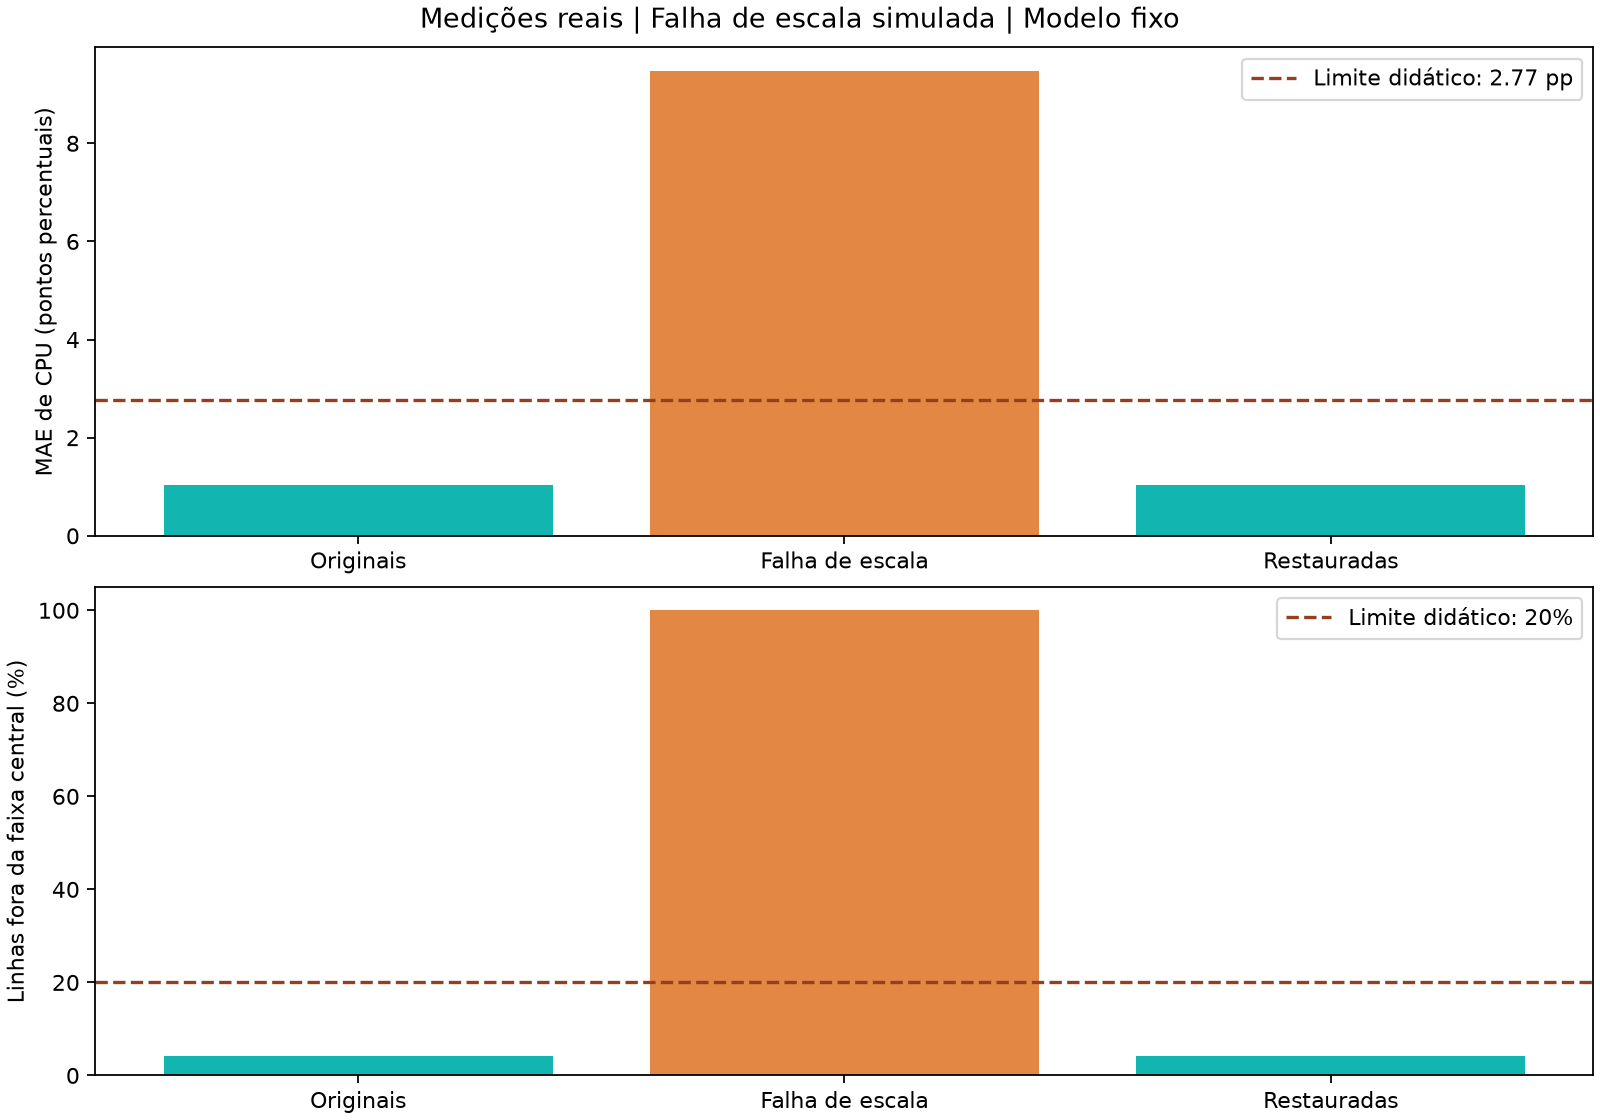

n  mae_original_pp  mae_falha_pp
cluster   vm                                             
vialactea achernar-001  27         3.117727     19.617864
          achernar-002  27         0.311101      5.204557
          achernar-003  27         0.310320      6.922259
          achernar-004  27         0.484622     10.616698
          achernar-005  27         0.337321      7.879650
          achernar-006  27         0.834588      7.640467
          achernar-007  27         3.817629     22.255591
          achernar-008  27         0.158102      2.577687
          achernar-009  27         3.273483     10.637210
          acrux-001     27         2.900630     12.462390

In [8]:
fig, axes = plt.subplots(2,1,figsize=(10,7),constrained_layout=True)
rotulos = ['Originais','Falha de escala','Restauradas']
cores = ['#12b5b0','#e28744','#12b5b0']
axes[0].bar(rotulos,[r['mae_pp'] for r in resultados],color=cores)
axes[0].axhline(limite_mae,linestyle='--',color='#944020',label=f'Limite didático: {limite_mae:.2f} pp')
axes[0].set_ylabel('MAE de CPU (pontos percentuais)'); axes[0].legend()
axes[1].bar(rotulos,[100*r['fracao_fora_faixa_central'] for r in resultados],color=cores)
axes[1].axhline(20,linestyle='--',color='#944020',label='Limite didático: 20%')
axes[1].set_ylabel('Linhas fora da faixa central (%)'); axes[1].set_ylim(0,105);axes[1].legend()
fig.suptitle('Medições reais | Falha de escala simulada | Modelo fixo')
fig.savefig(EVIDENCIAS/'monitoramento.png',dpi=160);plt.close(fig)
display(Image(filename=str(EVIDENCIAS/'monitoramento.png')))
por_vm = avaliacao[chaves].copy()
por_vm['erro_original_pp'] = np.abs(avaliacao.used_pct_cpu.to_numpy()-modelo.predict(x_original))
por_vm['erro_falha_pp'] = np.abs(avaliacao.used_pct_cpu.to_numpy()-modelo.predict(x_falha))
resumo_vm = por_vm.groupby(['cluster','vm']).agg(n=('date','size'),mae_original_pp=('erro_original_pp','mean'),mae_falha_pp=('erro_falha_pp','mean'))
resumo_vm.to_csv(EVIDENCIAS/'erro_por_vm.csv')
display(resumo_vm.head(10))

## 6. Interpretar e reproduzir
As medições reais sustentam o treino e a avaliação. A falha de escala foi criada somente em uma cópia das entradas. Não há evidência de que essa falha ocorreu no ambiente de origem, nem de mudança natural na relação entre carga e CPU.

Este experimento demonstra perda de qualidade das previsões. Não implementa API, alerta externo, retreinamento ou recuperação de produção. Os limites são didáticos. Antes de automatizar uma resposta, avalie erro por VM, sazonalidade e falsos alarmes.

**Exercícios:** comparar com persistência (CPU de ontem); variar os cortes temporais; medir erro por faixas de utilização; experimentar atraso dos valores observados; testar mudança na entrada que não afete o erro.

In [9]:
persistencia = float(mean_absolute_error(avaliacao.used_pct_cpu,avaliacao.cpu_lag))
evidencia = dict(fonte='RMC_Recursos_vialactea.xlsx',tipo='dados_reais_com_falha_de_escala_simulada',n_cpu=len(cpu),n_mem=len(mem),vms_fonte=cpu.vm.nunique(),vms_pares=pares.vm.nunique(),n_treino=len(treino),n_referencia=len(referencia),n_avaliacao=len(avaliacao),mae_referencia_pp=mae_ref,mae_persistencia_pp=persistencia,limite_mae_pp=limite_mae,limite_entrada=limite_entrada,resultados=resultados,modelo_sha256=hash_inicial,modelo_inalterado=assinatura()==hash_inicial,python=platform.python_version())
(EVIDENCIAS/'resultados.json').write_text(json.dumps(evidencia,ensure_ascii=False,indent=2),encoding='utf-8')
print(f'Comparação com persistência: MAE {persistencia:.4f} pp')
print('Resultados e erro por VM salvos em evidencias/.')

Comparação com persistência: MAE 0.9663 pp
Resultados e erro por VM salvos em evidencias/.
